# Emotion Detection using Transfer Learning

Train a model to recognise 7 emotions from faces using MobileNetV2, then try it live on the webcam. Dataset: FER-2013 (Kaggle).

Note: I'm using `opencv-python<5` because version 5 doesn't have `CascadeClassifier`, which the webcam part needs.

In [ ]:
%pip install tensorflow "opencv-python<5" matplotlib numpy

In [ ]:

import json
import numpy as np
import matplotlib.pyplot as plt
import cv2
print(cv2.__version__)
print(hasattr(cv2, "CascadeClassifier"))

from tensorflow import keras
from tensorflow.keras import layers

print("All libraries loaded")

## Settings and data

In [3]:
DATA_FOLDER ="archive (2)"
IMG_SIZE = (96, 96)
BATCH_SIZE = 64
EPOCHS_PHASE_A = 15
EPOCHS_PHASE_B = 15

In [4]:
train_data = keras.utils.image_dataset_from_directory(
    f"{DATA_FOLDER}/train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    color_mode="rgb",           # MobileNet expects 3 colour channels
    label_mode="categorical")

test_data = keras.utils.image_dataset_from_directory(
    f"{DATA_FOLDER}/test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    color_mode="rgb", label_mode="categorical", shuffle=False)

class_names = train_data.class_names
print("Emotions found:", class_names)

# Save emotion names so the live webcam step uses the same order
with open("class_names.json", "w") as f:
    json.dump(class_names, f)

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.
Emotions found: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## Look at some training images

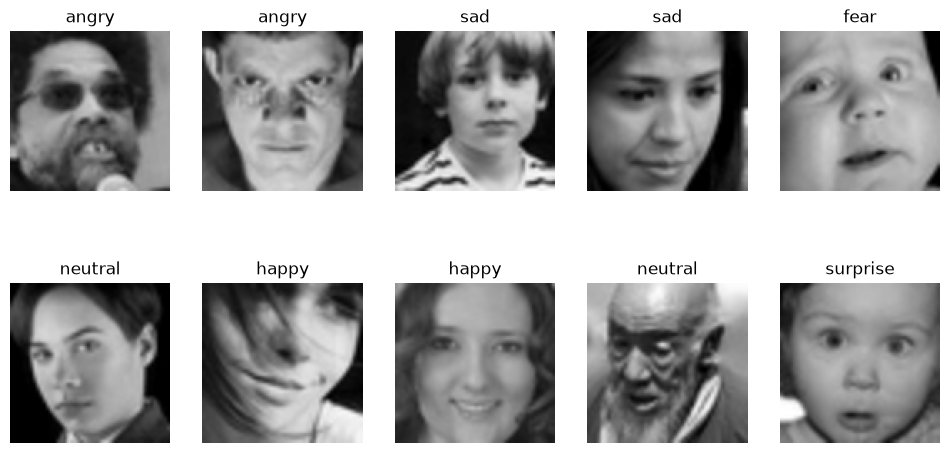

In [6]:
plt.figure(figsize=(12, 6))
for images, labels in train_data.take(1):
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[np.argmax(labels[i])])
        plt.axis("off")
plt.show()

## Build the model

MobileNetV2 is frozen, with augmentation and a new 7-class classifier on top.

In [7]:
base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet")
base_model.trainable = False     # FREEZE the borrowed brain

print("Borrowed MobileNetV2 with", len(base_model.layers), "layers (all frozen for now)")

Borrowed MobileNetV2 with 154 layers (all frozen for now)


In [8]:
# Small random changes to each image = more variety for the model to learn from
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)    # MobileNet wants pixel values from -1 to 1
x = base_model(x, training=False)                # the borrowed brain
x = layers.GlobalAveragePooling2D()(x)           # squeeze the features into a list
x = layers.Dropout(0.3)(x)                       # helps avoid just memorising
outputs = layers.Dense(len(class_names), activation="softmax")(x)   # 7 emotion scores

model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Training

Phase A: train only the new top layer. Phase B: fine-tune the last 30 layers of MobileNetV2 with a small learning rate.

(The test folder is used as validation here, so there is no separate test set.)

In [9]:
# Phase "A"
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])

history_a = model.fit(train_data, validation_data=test_data, epochs=EPOCHS_PHASE_A)

Epoch 1/15


c:\CNN\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


449/449 ━━━━━━━━━━━━━━━━━━━━ 131s 283ms/step - accuracy: 0.3314 - loss: 1.8391 - val_accuracy: 0.4153 - val_loss: 1.5083
Epoch 2/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 180s 400ms/step - accuracy: 0.3972 - loss: 1.5790 - val_accuracy: 0.4167 - val_loss: 1.4822
Epoch 3/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 191s 424ms/step - accuracy: 0.4078 - loss: 1.5506 - val_accuracy: 0.4181 - val_loss: 1.4783
Epoch 4/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 209s 440ms/step - accuracy: 0.4109 - loss: 1.5375 - val_accuracy: 0.4270 - val_loss: 1.4803
Epoch 5/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 198s 430ms/step - accuracy: 0.4121 - loss: 1.5340 - val_accuracy: 0.4387 - val_loss: 1.4558
Epoch 6/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 389s 867ms/step - accuracy: 0.4150 - loss: 1.5262 - val_accuracy: 0.4347 - val_loss: 1.4669
Epoch 7/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 223s 493ms/step - accuracy: 0.4166 - loss: 1.5263 - val_accuracy: 0.4284 - val_loss: 1.4584
Epoch 8/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 250s 558ms/step - accuracy: 0.4162 - loss: 1.52

In [ ]:
# Phase "B" - unfreeze some of the borrowed brain and train again
base_model.trainable = True
for layer in base_model.layers[:-30]:      # keep early layers frozen
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),   # tiny steps
              loss="categorical_crossentropy", metrics=["accuracy"])

history_b = model.fit(train_data, validation_data=test_data, epochs=EPOCHS_PHASE_B)

Epoch 1/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 197s 404ms/step - accuracy: 0.3247 - loss: 2.1863 - val_accuracy: 0.4042 - val_loss: 1.7031
Epoch 2/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 215s 479ms/step - accuracy: 0.3746 - loss: 1.8721 - val_accuracy: 0.4316 - val_loss: 1.6449
Epoch 3/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 288s 641ms/step - accuracy: 0.3930 - loss: 1.7276 - val_accuracy: 0.4430 - val_loss: 1.6038
Epoch 4/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 244s 538ms/step - accuracy: 0.4139 - loss: 1.6136 - val_accuracy: 0.4529 - val_loss: 1.5475
Epoch 5/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 218s 486ms/step - accuracy: 0.4260 - loss: 1.5484 - val_accuracy: 0.4657 - val_loss: 1.4894
Epoch 6/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 200s 446ms/step - accuracy: 0.4438 - loss: 1.4828 - val_accuracy: 0.4689 - val_loss: 1.4501
Epoch 7/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 228s 507ms/step - accuracy: 0.4510 - loss: 1.4500 - val_accuracy: 0.4770 - val_loss: 1.4070
Epoch 8/15
449/449 ━━━━━━━━━━━━━━━━━━━━ 189s 419ms/step - accuracy: 0.4614 -

## Results

Final accuracy is about 51.9%. The classes are imbalanced (a lot more "happy" than "disgust" images), so this number hides how the model does on the rare classes.

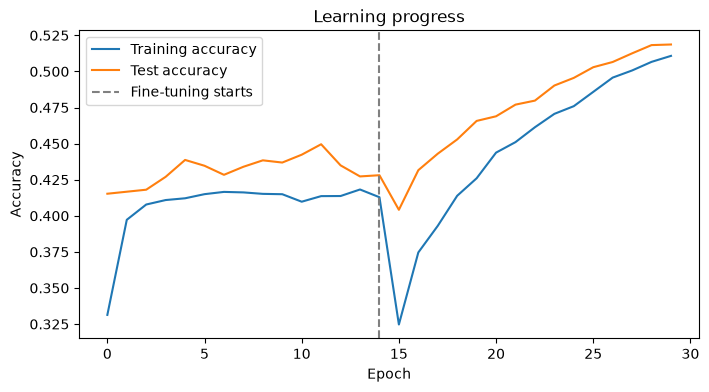

113/113 ━━━━━━━━━━━━━━━━━━━━ 38s 334ms/step - accuracy: 0.5187 - loss: 1.2750
Final test accuracy: 51.9%


In [ ]:
acc = history_a.history["accuracy"] + history_b.history["accuracy"]
val = history_a.history["val_accuracy"] + history_b.history["val_accuracy"]

plt.figure(figsize=(8, 4))
plt.plot(acc, label="Training accuracy")
plt.plot(val, label="Validation accuracy")
plt.axvline(EPOCHS_PHASE_A - 1, color="grey", linestyle="--", label="Fine-tuning starts")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Learning progress")
plt.show()

loss, accuracy = model.evaluate(test_data)
print(f"Final test accuracy: {accuracy * 100:.1f}%")

## Save the model

In [12]:
model.save("emotion_model.keras")
print("Saved emotion_model.keras and class_names.json")

Saved emotion_model.keras and class_names.json


## Live webcam demo

Needs a webcam. Press `q` to quit, `s` to save a screenshot.

In [13]:
# Go with the LIVE with the webcam

# Face finder that comes free with OpenCV
face_finder = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

# Colours (BGR) and little face tags for each emotion
colours = {
    "angry": (0, 0, 255), "disgust": (0, 140, 0), "fear": (160, 0, 160),
    "happy": (0, 215, 255), "neutral": (200, 200, 200),
    "sad": (255, 120, 0), "surprise": (0, 165, 255),
}
tags = {"angry": ">:(", "disgust": "x_x", "fear": "O_O", "happy": ":D",
        "neutral": ":|", "sad": ":(", "surprise": ":O"}

cam = cv2.VideoCapture(0)      # 0 = default webcam
if not cam.isOpened():
    raise RuntimeError("Could not open webcam. Close other apps using it and run this cell again.")

print("Webcam started. Click the video window, then press 'q' to quit.")

try:
    while True:
        ok, frame = cam.read()
        if not ok:
            break

        frame = cv2.flip(frame, 1)                       # mirror view
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)   # face finder likes grey images

        # STEP A: find faces
        faces = face_finder.detectMultiScale(gray, scaleFactor=1.3, minNeighbors=5,
                                             minSize=(80, 80))

        for (x, y, w, h) in faces:
            # STEP B: cut out the face and prepare it like the training images
            face = gray[y:y + h, x:x + w]
            face = cv2.resize(face, IMG_SIZE)
            face = cv2.cvtColor(face, cv2.COLOR_GRAY2RGB)
            face = np.expand_dims(face, axis=0)

            # STEP C: ask the model
            probs = model.predict(face, verbose=0)[0]
            best = int(np.argmax(probs))
            emotion = class_names[best]
            confidence = probs[best] * 100
            colour = colours.get(emotion, (255, 255, 255))

            # STEP D: draw the result
            cv2.rectangle(frame, (x, y), (x + w, y + h), colour, 3)
            label = f"{emotion.upper()} {tags.get(emotion, '')}  {confidence:.0f}%"
            cv2.putText(frame, label, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, colour, 2)

        # Live bars for ALL emotions (great for discussion!)
        if len(faces) > 0:
            for i, name in enumerate(class_names):
                bar_len = int(probs[i] * 150)
                top = 20 + i * 28
                cv2.rectangle(frame, (10, top), (10 + bar_len, top + 18),
                              colours.get(name, (255, 255, 255)), -1)
                cv2.putText(frame, f"{name} {probs[i] * 100:.0f}%", (170, top + 14),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)

        cv2.imshow("Emotion Detector (q = quit, s = screenshot)", frame)

        key = cv2.waitKey(1) & 0xFF
        if key == ord("q"):
            break
        if key == ord("s"):
            cv2.imwrite("screenshot.png", frame)
            print("Saved screenshot.png")

finally:
    # Always runs, even if something goes wrong, so the webcam is released
    cam.release()
    cv2.destroyAllWindows()
    for _ in range(4):
        cv2.waitKey(1)       # helps the window close properly on Mac
    print("Webcam stopped.")

Webcam started. Click the video window, then press 'q' to quit.
Webcam stopped.
